# create_agent 函数说明

## 功能概述

创建一个代理图（agent graph），在循环中调用工具，直到满足停止条件。

更多详情请访问 [Agents](https://docs.langchain.com/oss/python/langchain/agents) 文档。

## 参数说明

### model
代理使用的语言模型。

- 可以是字符串标识符（如 `"openai:gpt-4"`）或直接的聊天模型实例（如 `ChatOpenAI` 或其他 LangChain 聊天模型）
- 支持的模型字符串完整列表，请参见 `init_chat_model` 文档
- 💡 更多信息请参见 [Models](https://docs.langchain.com/oss/python/langchain/models) 文档

### tools
工具列表、字典或可调用对象。

- 如果为 `None` 或空列表，代理将只包含一个模型节点，不会有工具调用循环
- 💡 更多信息请参见 [Tools](https://docs.langchain.com/oss/python/langchain/tools) 文档

### system_prompt
LLM 的可选系统提示词。

- 可以是字符串（将被转换为 `SystemMessage`）或直接的 `SystemMessage` 实例
- 系统消息会在调用模型时添加到消息列表的开头

### middleware
应用于代理的中间件实例序列。

- 中间件可以在各个阶段拦截和修改代理行为
- 💡 更多信息请参见 [Middleware](https://docs.langchain.com/oss/python/langchain/middleware) 文档

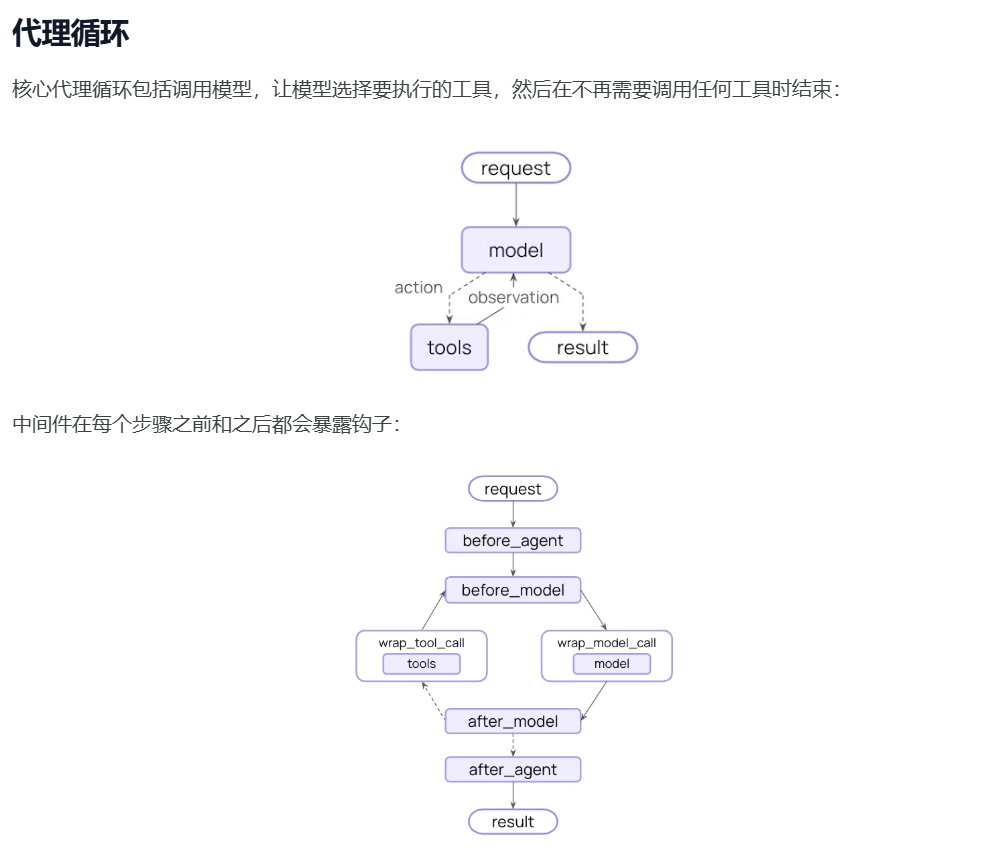

### response_format
结构化响应的可选配置。

- 可以是 `ToolStrategy`、`ProviderStrategy` 或 Pydantic 模型类
- 如果提供，代理将在对话流程中处理结构化输出
- 原始模式将根据模型能力包装到适当的策略中
- 💡 更多信息请参见 [Structured output](https://docs.langchain.com/oss/python/langchain/structured-output) 文档

### state_schema
扩展 `AgentState` 的可选 `TypedDict` 模式。


- class AgentState(TypedDict):

    messages: Annotated[list[AnyMessage], add_messages]

- 提供时 `AgentState` 与自己定义的State 进行合并，目的就是去扩充我们的State

### context_schema
传自己定义的Context的类型 ，直接的内容通过invoke的context传入

### checkpointer
可选的检查点保存器对象。

- 用于持久化单个线程（如单次对话）的图状态（例如作为聊天记忆）

### store
可选的存储对象。

- 用于跨多个线程（如多次对话/多用户）持久化数据

### interrupt_before
可选的节点名称列表，在这些节点之前中断。

- 适用于在执行操作前添加用户确认或其他中断

### interrupt_after
可选的节点名称列表，在这些节点之后中断。

- 适用于直接返回或对输出进行额外处理

### debug
是否启用图执行的详细日志记录。

- 启用时，会打印每个节点执行、状态更新和转换的详细信息
- 适用于调试中间件行为和理解代理执行流程

### name
`CompiledStateGraph` 的可选名称。

- 当将代理图作为子图节点添加到另一个图时，会自动使用此名称
- 特别适用于构建多代理系统

### cache
可选的 `BaseCache` 实例，用于启用图执行缓存。

## 返回值

返回一个已编译的 `StateGraph`，可用于聊天交互。

## 异常

**AssertionError**: 如果提供了重复的中间件实例。

## 工作原理

代理节点使用消息列表调用语言模型（应用系统提示词后）。如果结果中的 `AIMessage` 包含 `tool_calls`，图将调用这些工具。工具节点执行工具并将响应作为 `ToolMessage` 对象添加到消息列表中。然后代理节点再次调用语言模型。此过程重复进行，直到响应中不再包含 `tool_calls`。最后代理返回完整的消息列表。

## 使用示例

In [ ]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain_ollama import ChatOllama
model = ChatOllama(model="qwen3:8b",base_url="http://localhost:11434")

@tool
def check_weather(location: str) -> str:
    '''返回指定位置的天气预报'''
    return f"{location} 总是阳光明媚"


graph = create_agent(
    model=model,
    tools=[check_weather],
    system_prompt="你是一个有帮助的助手",
)

inputs = {"messages": [{"role": "user", "content": "旧金山的天气怎么样"}]}
for chunk in graph.stream(inputs, stream_mode="updates"):
    print(chunk)

## 核心要点总结

1. **循环工具调用**：代理会自动循环调用工具，直到 LLM 不再请求工具调用
2. **状态管理**：通过 `checkpointer` 和 `store` 实现会话持久化
3. **可扩展性**：通过 `middleware` 和 `state_schema` 自定义行为
4. **调试友好**：支持中断点和详细日志
5. **多代理支持**：可以作为子图嵌入到更大的系统中

## 相关文档链接

- [Agents 文档](https://docs.langchain.com/oss/python/langchain/agents)
- [Models 文档](https://docs.langchain.com/oss/python/langchain/models)
- [Tools 文档](https://docs.langchain.com/oss/python/langchain/tools)
- [Middleware 文档](https://docs.langchain.com/oss/python/langchain/middleware)
- [Structured output 文档](https://docs.langchain.com/oss/python/langchain/structured-output)

## response_format 模型输出用约束json  （很重要）

我们常使用的模型输出约束方式有三种：

- 第一种: 纯 Prompt 引导 加上json输出解释器  可靠性最弱

- 第二种：依赖于模型的Function Calling（ToolStrategy）

- 第三种：厂商在推理层面做了约束，保证模型 token 采样时只能生成符合 json schema的内容 百分百生成json格式但需要推理厂商支持（ProviderStrategy）



In [ ]:
'''
第二种：依赖于模型的Function Calling（ToolStrategy）

'''

'''
用法1
'''
from langchain_openai import ChatOpenAI
from pydantic import BaseModel,Field

model = ChatOpenAI(
    model="qwen3-max",
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key="sk-ws-H.RYLEXRL.gLta.MEYCIQCcevt5KrUbUtc_N5JKOTHW81fzvBlrJYF4XBw_mzN6AgIhAMAHz6-dE8PU2FRqm4-uOqUimgEdVcaWo-q3Z5HC97Xg",
    extra_body={"enable_thinking": False}
)

class output_parser(BaseModel):
    weather: str = Field(description="天气预报")
    window : str = Field(description="风力大小")
    temperature: int = Field(description="温度")



llm = model.with_structured_output(output_parser,method="function_calling")

res = llm.invoke("旧金山的天气很好，小雨，20度，东南风")

print(res)

'''
用法2 在create_agent中使用

但是模型参数太小识别效果会比较差 建议测试的时候使用在线的大模型效果会很好
'''
from langchain.agents import create_agent
from langchain.agents.structured_output import ToolStrategy
from langchain.tools import tool
from langchain_ollama import ChatOllama
from pydantic import BaseModel,Field
from langchain_openai import ChatOpenAI



model = ChatOpenAI(
    model="qwen3-max",
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key="sk-ws-H.RYLEXRL.gLta.MEYCIQCcevt5KrUbUtc_N5JKOTHW81fzvBlrJYF4XBw_mzN6AgIhAMAHz6-dE8PU2FRqm4-uOqUimgEdVcaWo-q3Z5HC97Xg",
    extra_body={"enable_thinking": False}
)
class output_parser(BaseModel):
    weather: str = Field(description="天气预报")
    window : str = Field(description="风力大小")
    temperature: int = Field(description="温度")


@tool
def check_weather(location: str):
    '''返回指定位置的天气预报'''
    return f"{location} 总是阳光明媚,有风,温度20度"



graph = create_agent(
    model=model,
    tools=[check_weather],
    system_prompt="你是一个有帮助的助手",
    response_format= ToolStrategy(output_parser)
)

inputs = {"messages": [{"role": "user", "content": "旧金山的天气怎么样"}]}

res = graph.invoke(inputs)
print(res.get("structured_response"))

In [ ]:
'''
第三种：厂商在推理层面做了约束，保证模型 token 采样时只能生成符合 json schema的内容 百分百生成json格式但需要推理厂商支持
'''

"""
Openai支持

直接使用 OpenAI 兼容接口的 response_format 参数，让模型只输出合法 JSON

response_format + JSON Schema（精确约束）

部分模型（如 OpenAI gpt-4o、Qwen3 系列）还支持在 response_format 中直接传入 JSON Schema，实现精确的字段约束：

"""
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="qwen3-max",
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key="sk-ws-H.RYLEXRL.gLta.MEYCIQCcevt5KrUbUtc_N5JKOTHW81fzvBlrJYF4XBw_mzN6AgIhAMAHz6-dE8PU2FRqm4-uOqUimgEdVcaWo-q3Z5HC97Xg",
    model_kwargs={
        "response_format": {
            "type": "json_schema",
            "json_schema": {
                "name": "weather_info",
                "schema": {
                    "type": "object",
                    "properties": {
                        "city": {"type": "string", "description": "城市名称"},
                        "weather": {"type": "string", "description": "天气状况"},
                        "temperature": {"type": "integer", "description": "温度"},
                        "wind": {"type": "string", "description": "风向"}
                    },
                    "required": ["city", "weather", "temperature", "wind"]
                }
            }
        }
    }
)

res = model.invoke("旧金山的天气很好，小雨，20度，东南风")
print(res.content)

'''
方式二
'''
from langchain_openai import ChatOpenAI
from pydantic import BaseModel,Field

model = ChatOpenAI(
    model="qwen3-max",
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key="sk-ws-H.RYLEXRL.gLta.MEYCIQCcevt5KrUbUtc_N5JKOTHW81fzvBlrJYF4XBw_mzN6AgIhAMAHz6-dE8PU2FRqm4-uOqUimgEdVcaWo-q3Z5HC97Xg",
    extra_body={"enable_thinking": False}
)

class output_parser(BaseModel):
    weather: str = Field(description="天气预报")
    window : str = Field(description="风力大小")
    temperature: int = Field(description="温度")



llm = model.with_structured_output(output_parser,method="json_schema")

res = llm.invoke("旧金山的天气很好，小雨，20度，东南风")

print(res)


In [ ]:
"""
在create_agent中使用  使用时请使用openai的客户端

ProviderStrategy 通过模型原生的 response_format 参数，设置 type: "json_schema"
"""

from langchain.agents import create_agent
from langchain.agents.structured_output import ProviderStrategy
from langchain.tools import tool
from pydantic import BaseModel,Field
from langchain_openai import ChatOpenAI

from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model="qwen3-max",
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key="sk-ws-H.RYLEXRL.gLta.MEYCIQCcevt5KrUbUtc_N5JKOTHW81fzvBlrJYF4XBw_mzN6AgIhAMAHz6-dE8PU2FRqm4-uOqUimgEdVcaWo-q3Z5HC97Xg",
    extra_body={"enable_thinking": False}
)


class output_parser(BaseModel):
    weather: str = Field(description="天气预报")
    window : str = Field(description="风力大小")
    temperature: int = Field(description="温度")


@tool
def check_weather(location: str):
    '''返回指定位置的天气预报'''
    return f"{location} 总是阳光明媚,有风,温度20度"


graph = create_agent(
    model=model,
    tools=[check_weather],
    system_prompt="你是一个有帮助的助手",
    response_format= ProviderStrategy(output_parser)
)

inputs = {"messages": [{"role": "user", "content": "旧金山的天气怎么样"}]}

res = graph.invoke(inputs)
print(res)


## Middleware  中间件

### wrap_model_call  缠绕式中间件

In [ ]:
'''
用途： 从函数创建带有 wrap_model_call 钩子的中间件。
将一个带有 handler 回调的函数转换为中间件，该中间件可以拦截模型调用、实现重试逻辑、处理错误，以及重写响应。


参数	说明
func	接收 (request, handler) 的函数，调用 handler(request) 来执行模型，返回 ModelResponse 或 AIMessage。<br>Request 包含 state 和 runtime。
state_schema	自定义状态模式。默认为 AgentState。
tools	要注册到此中间件的额外工具。
name	中间件类名。默认为函数名。
'''

In [ ]:
from langchain.agents.middleware import (SummarizationMiddleware,before_agent,
                                         AgentState, before_model,
                                         dynamic_prompt,
                                         AgentMiddleware,
                                         wrap_model_call,
                                         wrap_tool_call,
                                         ModelRequest,
                                         ModelResponse
                                         )
from langchain.tools.tool_node import ToolCallRequest
from langchain.messages import ToolMessage
from typing import Callable   

'''
from typing import Callable
# 表示：一个接收 int 参数、返回 str 的函数
def run(func: Callable[[int], str]):
    result = func(42)
    print(result)


我们传入的 store 与 context 可以通过
user_name = request.runtime.context.get
role = request.runtime.store.get
获取config 
from langgraph.config import get_config
'''

'''
示例 1：基本重试逻辑
'''
from langchain.agents.middleware import (
                                         wrap_model_call,
                                         ModelRequest,
                                         ModelResponse
                                         )
from typing import Callable  

from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.messages import AIMessage
from langgraph.config import get_config

model1 = ChatOpenAI(
    model="qwen3:8b",          # Ollama 中已拉取的模型名
    base_url="http://localhost:11434/v1",  # 注意要加 /v1
    api_key="ollama" ,         # 随便填，Ollama 不验证 key，但不能为空
)


@wrap_model_call
def retry_model(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse],  # handler 是一个函数
) -> ModelResponse:
    for attempt in range(3):
        try:
            return handler(request)  # 调用这个函数，传入 request，得到 response
        except Exception as e:
            if attempt == 2:
                raise
            print(f"Retry {attempt + 1}/3 after error: {e}") 



agent = create_agent(
    model=model1,
    tools=[],
    middleware=[retry_model],
)

res = agent.invoke({"messages":[("user","旧金山的天气怎么样")]})
print(res)

"""
示例 2：模型降级/备用模型
"""
from langchain.agents.middleware import (wrap_model_call,
                                         ModelRequest,
                                         ModelResponse
                                         )
from typing import Callable 

from langchain_openai import ChatOpenAI
from langchain.agents import create_agent

model1 = ChatOpenAI(
    model="qwen3:10",          # Ollama 中已拉取的模型名
    base_url="http://localhost:11434/v1",  # 注意要加 /v1
    api_key="ollama" ,         # 随便填，Ollama 不验证 key，但不能为空
)

model2 = ChatOpenAI(
    model="qwen3-max",
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key="sk-9f700272dd30454283103d3e129958d9",
)


@wrap_model_call
def fallback_model(request, handler):
    try:
        return handler(request)
    except Exception:
        request = request.override(model=model2)
        return handler(request)

agent = create_agent(
    model=model1,
    tools=[],
    middleware=[fallback_model],
)

res = agent.invoke({"messages":[("user","旧金山的天气怎么样")]})
print(res)

"""
示例 3：重写响应内容（返回完整的 ModelResponse，调用了模型）
"""

from langchain.agents.middleware import (
                                         wrap_model_call,
                                         ModelRequest,
                                         ModelResponse
                                         )
from typing import Callable  

from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain_core.messages import AIMessage
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import InMemorySaver
from dataclasses import dataclass

@dataclass
class Context:
    user_id: str




model1 = ChatOpenAI(
    model="qwen3:8b",          # Ollama 中已拉取的模型名
    base_url="http://localhost:11434/v1",  # 注意要加 /v1
    api_key="ollama" ,         # 随便填，Ollama 不验证 key，但不能为空
)

@wrap_model_call
def uppercase_responses(request, handler):
    response = handler(request)
    print(response)
    ai_msg = response.result[0]
    return ModelResponse(
        result=[AIMessage(content="我被改了")],
        structured_response=response.structured_response,
    )


agent = create_agent(
    model=model1,
    tools=[],
    middleware=[uppercase_responses],
    store=InMemoryStore(),
    checkpoint=InMemorySaver(),
    context_schema=Context,
)

res = agent.invoke({"messages":[("user","你是谁用10个字回答")]},config={"configurable":{"thread_id":"123"}},context=Context(user_id="123"))

print(res)
'''
示例 4：简单返回 AIMessage（自动转换,没有使用模型）
'''
@wrap_model_call
def simple_response(request, handler):
    # AIMessage 会自动转换为 ModelResponse
    return AIMessage(content="Simple response")

## wrap_tool_call中间键

In [ ]:
from typing import Callable
from langchain.agents.middleware import wrap_tool_call
from langchain.tools.tool_node import ToolCallRequest
from langchain.messages import ToolMessage
import time

from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain.tools import tool

model1 = ChatOpenAI(
    model="qwen3:8b",          # Ollama 中已拉取的模型名
    base_url="http://localhost:11434/v1",  # 注意要加 /v1
    api_key="ollama" ,         # 随便填，Ollama 不验证 key，但不能为空
)

@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    return f"城市{city}的天气是晴天"
@wrap_tool_call
def log_tool_call(
    request: ToolCallRequest,
    handler: Callable[[ToolCallRequest], ToolMessage]
) -> ToolMessage:
    """记录每次工具调用的名称、参数和耗时"""
    tool_name = request.tool_call["name"]
    tool_args = request.tool_call["args"]
    print(f"[工具调用] {tool_name}，参数: {tool_args}")
    
    start = time.time()
    response = handler(request)
    elapsed = time.time() - start
    
    print(f"[工具结果] {tool_name} 耗时 {elapsed:.2f}s，结果: {response.content}")
    return response

agent = create_agent(
    model=model1,
    tools=[get_weather],
    middleware=[log_tool_call]
)
res = agent.invoke({"messages":[("user","旧金山的天气怎么样")]})
print(res)

In [ ]:
#示例 2：工具调用重试（出错自动重试）
from langchain.agents.middleware import (
                                         wrap_tool_call
                                         )
from typing import Callable
from langchain.agents.middleware import wrap_tool_call
from langchain.tools.tool_node import ToolCallRequest
from langchain.messages import ToolMessage
import time
from typing import Callable  


from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain.tools import tool

model1 = ChatOpenAI(
    model="qwen3:8b",          # Ollama 中已拉取的模型名
    base_url="http://localhost:11434/v1",  # 注意要加 /v1
    api_key="ollama" ,         # 随便填，Ollama 不验证 key，但不能为空
)

@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    return f"城市{city}的天气是晴天"
@wrap_tool_call
def retry_tool(
    request: ToolCallRequest,
    handler: Callable[[ToolCallRequest], ToolMessage]
) -> ToolMessage:
    """工具执行失败时自动重试最多 3 次"""
    for attempt in range(3):
        try:
            return handler(request)
        except Exception as e:
            if attempt == 2:
                raise
            print(f"工具 {request.tool_call['name']} 第 {attempt+1} 次失败: {e}，重试中...")

agent = create_agent(
    model=model1,
    tools=[get_weather],
    middleware=[retry_tool])

res = agent.invoke({"messages":[("user","旧金山的天气怎么样")]})
print(res)



In [ ]:
# 示例 3：工具调用权限拦截（黑名单屏蔽）
from langchain.agents.middleware import wrap_tool_call
from langchain_openai import ChatOpenAI

from langchain.agents import create_agent

from langchain_core.messages import AIMessage

from langchain.tools import tool
from langchain.tools.tool_node import ToolCallRequest
from langchain.messages import ToolMessage
import time

from dataclasses import dataclass


from typing import Callable
model = ChatOpenAI(
    model="qwen3.7-max",
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
    api_key="sk-ws-H.RYLEXRL.gLta.MEYCIQCcevt5KrUbUtc_N5JKOTHW81fzvBlrJYF4XBw_mzN6AgIhAMAHz6-dE8PU2FRqm4-uOqUimgEdVcaWo-q3Z5HC97Xg",
    extra_body={"enable_thinking": False}
)

####  工具黑白名单

from langgraph.checkpoint.memory import MemorySaver
from langgraph.config import get_config

@dataclass
class User:
    user_id: str

BLOCKED_TOOLS = {"user1":{"delete_file", "get_weather"}}  # 禁止调用的工具:


@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    return f"城市{city}的天气是晴天"
@wrap_tool_call
def log_tool_call(
    request: ToolCallRequest,
    handler: Callable[[ToolCallRequest], ToolMessage]
) -> ToolMessage:
    """记录每次工具调用的名称、参数和耗时"""
    user_id =  request.runtime.context.user_id
    if user_id in BLOCKED_TOOLS.keys():
        return ToolMessage(
            content=f"用户没有权限执行工具 {user_id} 已被系统禁用，无法执行。",
            tool_call_id=request.tool_call["id"], 
        ) #修改ToolMessage 必须要指定tool_call_id 
          #模型输出的 AI 消息（一条消息，但含多个 tool call）
          # 没有id无法将工具名称与返回的记过对应上


    response = handler(request)

    # return response


checkpoint = MemorySaver()

agent = create_agent(
    model=model,
    tools=[get_weather],
    middleware=[log_tool_call],
    context_schema=User,  #指定context的类型
    checkpointer=checkpoint,
)

res = agent.invoke({"messages":[("user","旧金山的天气怎么样")]},
config={"configurable":{"thread_id":"123","user_id":"user1"}},
context=User(user_id="user1")) # 配置上下文信息
print(res)

In [ ]:
# 示例 4：工具结果缓存（相同参数不重复调用）
from langchain.agents.middleware import (
                                         wrap_tool_call
                                         )
from typing import Callable
from langchain.agents.middleware import wrap_tool_call
from langchain.tools.tool_node import ToolCallRequest
from langchain.messages import ToolMessage
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain.tools import tool

model1 = ChatOpenAI(
    model="gpt-oss:latest",          # Ollama 中已拉取的模型名
    base_url="http://localhost:11434/v1",  # 注意要加 /v1
    api_key="ollama" ,         # 随便填，Ollama 不验证 key，但不能为空
)

@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    return f"城市{city}的天气是晴天"

_tool_cache = {}
@wrap_tool_call
def cache_tool_result(
    request: ToolCallRequest,
    handler: Callable[[ToolCallRequest], ToolMessage]
) -> ToolMessage:
    """对相同的工具+参数组合，直接返回缓存结果"""
    tool_name = request.tool_call["name"] 
    tool_args = str(sorted(request.tool_call["args"].items()))

    #将字典转换为键值对的视图，例如：dict_items([("city", "北京"), ("date", "2026-03-30")])
    #为什么是"视图"？ 视图的特点是动态反映字典的变化，不会复制数据
    #对键值对列表按键名字母顺序排序，确保相同参数的字典每次生成的顺序一致
    cache_key = f"{tool_name}:{tool_args}"
    
    if cache_key in _tool_cache:
        print(f"[缓存命中] {tool_name}")
        return _tool_cache[cache_key]
    
    response = handler(request)
    _tool_cache[cache_key] = response
    return response
agent = create_agent(
    model=model1,
    tools=[get_weather],
    middleware=[cache_tool_result]
)

res = agent.invoke({"messages":[("user","旧金山的天气怎么样")]})
print(res)


## SummarizationMiddleware 

功能：当对话消息积累到一定数量或 token 数时，自动用另一个模型压缩历史消息，避免上下文溢出。

In [ ]:
'''
参数	说明	示例值
model	做摘要的模型	任何 ChatModel
trigger	什么时候触发摘要	("messages", 10) / ("tokens", 3000) / ("fraction", 0.8)
keep	摘要后保留多少原始消息	("messages", 4) / ("tokens", 1000)
'''

from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware  #会话摘要 保证上下长度

from langchain_openai import ChatOpenAI
from langchain.tools import tool

from langgraph.checkpoint.memory import InMemorySaver
from pydantic import config


model1 = ChatOpenAI(model="qwen3:8b",base_url="http://localhost:11434/v1",api_key="ollama")  #摘要

model2= ChatOpenAI(model="qwen3-max",base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",api_key="sk-9f700272dd30454283103d3e129958d9")#会话


@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    return f"城市{city}的天气是晴天"


checkpointer = InMemorySaver()
config = {"configurable":{"thread_id":"123"}}
agent = create_agent(model=model2,
                     tools=[get_weather],
                     middleware=[SummarizationMiddleware(model=model1, #用那个模型做摘呀
                     trigger=("messages",5), #超过5条做摘要
                     keep=("messages",3))],#摘要后保留4条原始消息
                     checkpointer=checkpointer) 
    


while True:
    user_input = input("请输入问题: ")
    if user_input == "exit":
        break
    else:
        res = agent.invoke({"messages":[("user",user_input)]},config=config)
        print(res)

## dynamic_prompt 例子
功能：在每次调用模型前，根据当前 state（对话状态）或 context（运行时上下文）动态生成 system prompt，而不是固定一个 system_prompt 字符串。

In [ ]:
'''
例子 1：根据对话轮数改变 prompt
'''

from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain.agents.middleware import dynamic_prompt, ModelRequest
from langgraph.checkpoint.memory import InMemorySaver

model = ChatOpenAI(
    model="qwen3:8b",
    base_url="http://localhost:11434/v1",
    api_key="ollama",
)


#例子1：根据对话轮数改变 prompt

@dynamic_prompt

def adaptive_prompt(request: ModelRequest) -> str:
    print(request)
    original_prompt = request.system_message.content if request.system_message else "" #原来的提示词
    print(original_prompt)  # 打印出 "我是周润发"

    msg_count = len(request.state["messages"])

    if msg_count >3:
        return "你现在得叫我坤哥,忘记之前的名字"
    return original_prompt 


checkpointer = InMemorySaver()
agent = create_agent(model=model,middleware=[adaptive_prompt],system_prompt="我是周润发",checkpointer=checkpointer)
config = {"configurable":{"thread_id":"123"}}

while True:
    user_input = input("请输入问题: ")
    if user_input == "exit":
        break
    else:
        res = agent.invoke({"messages":[("user",user_input)]},config=config)
        print(res)


In [ ]:
'''
例子 2：根据运行时 context 注入用户信息
'''
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langchain.agents.middleware import dynamic_prompt, ModelRequest

model = ChatOpenAI(
    model="qwen3:8b",
    base_url="http://localhost:11434/v1",
    api_key="ollama",
)


@dynamic_prompt
def user_aware_prompt(request: ModelRequest) -> str:
    """从 context 中读取用户名，生成个性化 prompt"""
    # context 通过 agent.invoke({"input": ...}, config={"configurable": {"user_name": "张三"}}) 传入
    user_name = request.runtime.context.get("user_name", "用户")
    role = request.runtime.context.get("role", "普通用户")
    return f"你正在为 {user_name}（身份：{role}）提供服务，请根据其身份调整回答风格。"

agent = create_agent(
    model=model,
    tools=[],
    middleware=[user_aware_prompt],
    context_schema=dict,
)

result = agent.invoke(
    {"messages": [{"role": "user", "content": "帮我写一份报告大纲"}]},
    context={"user_name": "张三", "role": "高中教师"},
)
print(result)
